# Day 4

Data Source: https://www.torsofdartmoor.co.uk/map.php

### 1. Extract the tors from website above.

Right click on the map and click View Frame Source. Select all and copy to a .html file. Extract using the code below.

In [3]:
import csv
import html
import json
import re
import sys
from pathlib import Path

In [5]:
src = Path("map_source.html")
text = src.read_text(encoding="utf-8", errors="ignore")

In [7]:
# 1. SET UP "SEARCH PATTERNS"

# On the website, every tor is written like this (two lines of code):
#   L.marker([50.48, -3.94], {icon: public_Icon})
#   marker.bindPopup("...the tor's name, link and grid reference...");
#
# This pattern finds each of those pairs and grabs 4 things:
#   1. the latitude        (e.g. 50.488986)
#   2. the longitude       (e.g. -3.945926)
#   3. the icon type       (e.g. "public" - tells us the access status)
#   4. the popup text      (the little info box that appears when you
#                           click a tor on their map)
marker_re = re.compile(
    r"L\.marker\(\[\s*(-?[\d.]+)\s*,\s*(-?[\d.]+)\s*\]\s*,\s*\{icon:\s*(\w+?)_Icon\}\)"
    r".*?bindPopup\(\"(.*?)\"\);",
    re.S,   # lets the search carry on across line breaks
)

# The tor's NAME - it sits between  target='_blank'>  and  </a>
name_re = re.compile(r"target='_blank'>(.*?)</a>")

# The tor's web ID - the bit after "tor=" in its link
# (e.g. "a-head-stone" from ...tor-page.php?tor=a-head-stone)
slug_re = re.compile(r"tor=([^'\"]+)")

# The OS GRID REFERENCE - comes after "Grid:"
# (two capital letters, then numbers, e.g. "SX 62058 67274")
grid_re = re.compile(r"Grid:\s*([A-Z]{2}[\d ]+?)\s*</div>")

# 2: A TRANSLATION LIST
# The website uses short code words for each icon colour. This list
# swaps them for readable descriptions.
LABELS = {
    "public": "Public",
    "public_pp": "Public (part private)",
    "private_vis": "Private (visible from public land)",
    "private_acc": "Private (with access)",
    "private_fee": "Private (fee to visit)",
    "private_seek": "Private (seek permission)",
    "private_no": "Private (no access)",
    "okehampton": "Okehampton firing range",
    "merrivale": "Merrivale firing range",
    "willsworthy": "Willsworthy firing range",
}

# 3: GO THROUGH THE PAGE AND COLLECT EVERY TOR

rows = []   # an empty list for adding each tor collected

# findall = "find EVERY match of the marker pattern on the page".
# Each match hands us the 4 things we asked for: lat, lon, icon, popup.
for lat, lon, icon, popup in marker_re.findall(text):

    # Search inside this tor's popup for its name, web ID and grid ref
    name = name_re.search(popup)
    slug = slug_re.search(popup)
    grid = grid_re.search(popup)

    # Build one tidy record for this tor and add it to our list.
    rows.append({
        # name: fix web symbols (e.g. "&amp;" back to "&") and trim spaces
        "name": html.unescape(name.group(1)).strip() if name else "",

        # lat/lon: turn the text into an actual number
        "lat": float(lat),
        "lon": float(lon),

        # the raw icon code, plus its readable version from the list above
        "category": icon,
        "category_label": LABELS.get(icon, icon),

        # grid ref: squash any double spaces down to single spaces
        "grid_ref": " ".join(grid.group(1).split()) if grid else "",

        "slug": slug.group(1) if slug else "",
    })

# 4: SAFETY CHECK
if not rows:
    sys.exit("No markers found - check you saved the map frame source (map_full.php).")

# Save the output files in the same folder as the HTML file
out_dir = src.parent

# 5a: SAVE AS A SPREADSHEET (CSV)
with open(out_dir / "tors.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=rows[0].keys())  # column headers = name, lat, lon...
    w.writeheader()     # write the header row
    w.writerows(rows)   # write all the tors underneath

# STEP 5b: SAVE AS A MAP FILE (GeoJSON)
geojson = {
    "type": "FeatureCollection",   # "this file is a collection of map features"
    "features": [
        {
            "type": "Feature",
            "geometry": {"type": "Point", "coordinates": [r["lon"], r["lat"]]},
            "properties": {k: v for k, v in r.items() if k not in ("lat", "lon")},
        }
        for r in rows   # do this for every tor
    ],
}
with open(out_dir / "tors.geojson", "w", encoding="utf-8") as f:
    # ensure_ascii=False keeps special characters readable
    # indent=1 spreads it over lines so a human can read the file
    json.dump(geojson, f, ensure_ascii=False, indent=1)

# 6: PRINT A QUICK SUMMARY
print(f"Extracted {len(rows)} tors -> tors.csv, tors.geojson")

counts = {}   # a tally: category -> number of tors
for r in rows:
    counts[r["category_label"]] = counts.get(r["category_label"], 0) + 1

# print the tally, biggest category first
for label, n in sorted(counts.items(), key=lambda kv: -kv[1]):
    print(f"  {n:4d}  {label}")

Extracted 930 tors -> tors.csv, tors.geojson
   572  Public
   104  Private (with access)
   103  Private (visible from public land)
    63  Private (seek permission)
    28  Okehampton firing range
    16  Merrivale firing range
    14  Public (part private)
    14  Willsworthy firing range
    10  Private (fee to visit)
     6  Private (no access)


### 2. Run clustering algorithm

Open file, find the optimal parameters to run the DBSCAN clustering algorithm

In [42]:
import re
import pandas as pd
import geopandas as gpd
import numpy as np
from sklearn.cluster import HDBSCAN

In [21]:
raw = open("map_source.html", encoding="utf-8", errors="ignore").read()  # your filename
print("markers in HTML:", len(re.findall(r"L\.marker\(", raw)))

markers in HTML: 930


In [23]:
df = pd.read_csv("tors.csv")
print("rows extracted:", len(df))
print("missing names:", (df["name"] == "").sum())
print("duplicate names:", df["name"].duplicated().sum())
print("lat range:", df.lat.min(), df.lat.max(), "| lon range:", df.lon.min(), df.lon.max())

rows extracted: 930
missing names: 0
duplicate names: 0
lat range: 50.397133 50.734012 | lon range: -4.162451 -3.651792


#### Choosing HDBSCAN parameters

To find the best settings, run HDBSCAN with different combinations of:

- **`min_cluster_size` (mcs)**: the smallest number of tors that can form a cluster (tested 15–35)
- **`cluster_selection_method`**:
  - `eom` (excess of mass) favours fewer, larger, more stable clusters
  - `leaf` favours more, smaller, evenly sized clusters

This was done for two datasets: **all tors (930)** and **visitable tors only (644)**.

##### What each column means

| Column | Meaning |
|---|---|
| **clusters** | Number of groups found, i.e. the number of colours on the map |
| **noise** | Tors that don't belong to any cluster (shown as dim scattered points) |
| **largest** | Share of all tors in the biggest cluster, which shows whether one group dominates |

##### Criteria for a good map

- **6–10 clusters**: enough variety without too many colours to distinguish
- **Largest cluster under ~30%**: no single group dominates the map
- **Noise of roughly 15–35%**: enough scattered points for a firefly effect without thinning the clusters
- **Stability**: if neighbouring settings give the same result, the clusters reflect real structure in the data rather than a quirk of the parameters


In [44]:
VISITABLE = ["public", "public_pp", "okehampton", "merrivale", "willsworthy"]

gdf_all = gpd.read_file("tors.geojson").to_crs(27700)
gdf_vis = gdf_all[gdf_all["category"].isin(VISITABLE)].copy()
print(f"All: {len(gdf_all)} tors | Visitable: {len(gdf_vis)} tors\n")

def get_xy(g):
    return np.column_stack([g.geometry.x, g.geometry.y])

def sweep(g, label):
    xy_ = get_xy(g)
    print(f"--- {label} ---")
    for mcs in [15, 20, 25, 30, 35]:
        for method in ["eom", "leaf"]:
            lab = HDBSCAN(min_cluster_size=mcs, min_samples=5,
              cluster_selection_method=method, copy=True).fit_predict(xy_)
            n = lab.max() + 1
            sizes = np.bincount(lab[lab >= 0]) if n else [0]
            print(f"mcs {mcs:>3} | {method:<4} | clusters {n:>3} | "
                  f"noise {(lab == -1).sum():>4} ({(lab == -1).mean():.0%}) | "
                  f"largest {max(sizes)/len(xy_):.0%}")
    print()

sweep(gdf_all, "ALL TORS")
sweep(gdf_vis, "VISITABLE TORS")

All: 930 tors | Visitable: 644 tors

--- ALL TORS ---
mcs  15 | eom  | clusters  19 | noise  308 (33%) | largest 7%
mcs  15 | leaf | clusters  22 | noise  352 (38%) | largest 7%
mcs  20 | eom  | clusters  14 | noise  345 (37%) | largest 14%
mcs  20 | leaf | clusters  17 | noise  410 (44%) | largest 7%
mcs  25 | eom  | clusters   9 | noise  316 (34%) | largest 28%
mcs  25 | leaf | clusters  10 | noise  481 (52%) | largest 7%
mcs  30 | eom  | clusters   8 | noise  288 (31%) | largest 28%
mcs  30 | leaf | clusters   9 | noise  316 (34%) | largest 28%
mcs  35 | eom  | clusters   5 | noise  301 (32%) | largest 28%
mcs  35 | leaf | clusters   5 | noise  301 (32%) | largest 28%

--- VISITABLE TORS ---
mcs  15 | eom  | clusters  11 | noise  210 (33%) | largest 18%
mcs  15 | leaf | clusters  14 | noise  266 (41%) | largest 8%
mcs  20 | eom  | clusters   7 | noise  197 (31%) | largest 18%
mcs  20 | leaf | clusters  10 | noise  293 (45%) | largest 8%
mcs  25 | eom  | clusters   7 | noise  197 (31

#### Findings

**All tors**
- Small `mcs` (15–20) produces too many clusters (14–22).
- From `mcs` 25 upwards, the largest cluster jumps to **28%**. This is the dense group of mostly private tors in the eastern valleys chaining together into one large cluster.
- `leaf` with small `mcs` leaves too many tors as noise (up to 52%).
- **Best option: `mcs = 30`, `eom`**: 8 clusters, 31% noise, largest 28% (only just within the limit).

**Visitable tors**
- Removing private tors breaks up the dense eastern group, so clusters are more balanced overall (largest 18–21% instead of 28%).
- **Best option: `mcs = 20`, `eom`**: 7 clusters, 31% noise, largest 18%.
- The result is **stable**: `mcs = 20` and `mcs = 25` give an identical result, which suggests these 7 clusters are a genuine feature of the data.

#### Decision

The **visitable dataset with `mcs = 20`, `eom`** was chosen for the main map. It gives 7 well-balanced clusters that correspond to recognisable areas of Dartmoor (North Moor, Western Moor, Central Moor, Hound Tor & Haytor, Dart Valley, Lustleigh Cleave, Shaptor & Hennock), and the setting is stable.

#### Applying the final clustering

After choosing the parameters from the sweep, HDBSCAN is run once on each dataset with the selected settings. The results are written back into a single table so that both versions can be mapped from one file.

| Dataset | `min_cluster_size` | Method |
|---|---|---|
| All tors (930) | 30 | `eom` |
| Visitable tors (644) | 20 | `eom` |

**Visitable** tors are those in the categories *Public*, *Public (part private)*, and the three military firing ranges (*Okehampton*, *Merrivale*, *Willsworthy*), which are open access land when no live firing is taking place.

##### Helper functions

- **`run_hdbscan`** takes a set of tors, extracts their coordinates (in metres, British National Grid EPSG:27700), runs HDBSCAN, and returns a cluster number for each tor. A value of **−1** means the tor is **noise**: it doesn't belong to any cluster.
- **`name_clusters`** gives each cluster an automatic name by finding the cluster's centre (centroid) and taking the name of the tor closest to it. These names are placeholders and are later replaced with recognisable area names.

##### Clustering all tors

All 930 tors are clustered, and two new columns are added:

- `cluster_all`: the cluster number (−1 = noise)
- `name_all`: the cluster name ("Scattered" for noise)

##### Clustering visitable tors only

1. A True/False mask identifies which tors are visitable.
2. Every tor is first given a default `cluster_vis` value of **9999**, meaning *not visitable*.
3. HDBSCAN is run **only on the visitable tors**, and their 9999 is replaced with their actual cluster number.
4. Cluster names are added in `name_vis`, with two special labels:
   - **"Scattered"**: visitable tors not in any cluster (−1)
   - **"Not visitable"**: tors excluded from this analysis (9999)

Using 9999 rather than deleting the non-visitable tors keeps both results in **one file**, and those tors can easily be filtered out later in QGIS with `"cluster_vis" <> 9999`.

##### Output

The results are saved as:

- **`tors_clustered.geojson`**: point data for mapping in QGIS
- **`tors_clustered.csv`**: the same attributes as a table (without geometry)

| Field | Description |
|---|---|
| `cluster_all` | Cluster ID using all tors (−1 = noise) |
| `name_all` | Cluster name using all tors |
| `cluster_vis` | Cluster ID using visitable tors (−1 = noise, 9999 = not visitable) |
| `name_vis` | Cluster name using visitable tors |

A summary of the number of tors in each cluster is printed for both versions as a check.

> **Note:** Cluster numbers are arbitrary labels. Cluster 3 in the all-tors result has no relation to cluster 3 in the visitable result.

In [47]:
VISITABLE = ["public", "public_pp", "okehampton", "merrivale", "willsworthy"]

gdf = gpd.read_file("tors.geojson").to_crs(27700)

def run_hdbscan(g, mcs, method="eom"):
    xy_ = np.column_stack([g.geometry.x, g.geometry.y])
    return HDBSCAN(min_cluster_size=mcs, min_samples=5,
               cluster_selection_method=method, copy=True).fit_predict(xy_)

def name_clusters(g, col):
    names = {}
    for c in sorted(g.loc[g[col] >= 0, col].unique()):
        if c == 9999:
            continue
        pts = g[g[col] == c]
        centre = pts.geometry.union_all().centroid
        names[c] = pts.loc[pts.distance(centre).idxmin(), "name"]
    return names

# All tors
gdf["cluster_all"] = run_hdbscan(gdf, mcs=30)
names_all = name_clusters(gdf, "cluster_all")
gdf["name_all"] = gdf["cluster_all"].map(names_all).fillna("Scattered")

# Visitable tors only
vis_mask = gdf["category"].isin(VISITABLE)
gdf["cluster_vis"] = 9999
gdf.loc[vis_mask, "cluster_vis"] = run_hdbscan(gdf[vis_mask], mcs=20)
names_vis = name_clusters(gdf[vis_mask], "cluster_vis")
gdf["name_vis"] = gdf["cluster_vis"].map(names_vis)
gdf.loc[gdf["cluster_vis"] == -1, "name_vis"] = "Scattered"
gdf.loc[gdf["cluster_vis"] == 9999, "name_vis"] = "Not visitable"

# Save
gdf.to_file("tors_clustered.geojson", driver="GeoJSON")
gdf.drop(columns="geometry").to_csv("tors_clustered.csv", index=False)

print("ALL:\n", gdf.groupby(["cluster_all", "name_all"]).size(), "\n")
print("VISITABLE:\n", gdf.groupby(["cluster_vis", "name_vis"]).size())

ALL:
 cluster_all  name_all             
-1           Scattered                288
 0           Wildbanks Rocks           62
 1           Yes Tor (Walkhampton)    125
 2           Coombe Tor (Chagford)     33
 3           Hunt Tor                  58
 4           Metheral Hole             33
 5           Coffin Stone              33
 6           Great Lot Crags           36
 7           Cob Loaf, The            262
dtype: int64 

VISITABLE:
 cluster_vis  name_vis                        
-1           Scattered                           197
 0           Dinger Tor                          115
 1           Sharp Tor (Yartor Down)              50
 2           Yes Tor (Walkhampton)               105
 3           Wildbanks Rocks                      61
 4           Hillpark Copse Tor                   29
 5           Hawthorn Rock                        54
 6           Lustleigh Cleave Lower Sharpitor     33
 9999        Not visitable                       286
dtype: int64


### 3. Plot maps

Plot the maps and give a firefly style for visualisation

In [51]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

In [53]:
gdf = gpd.read_file("tors_clustered.geojson").to_crs(27700)

In [55]:
BG = "#05070d"
PALETTE = ["#ff5c7a", "#5ec8ff", "#4dffc3", "#ffa64d", "#ffe14d",
           "#c77dff", "#7dff6b", "#ff8de0", "#8da9ff", "#ffd1a1"]

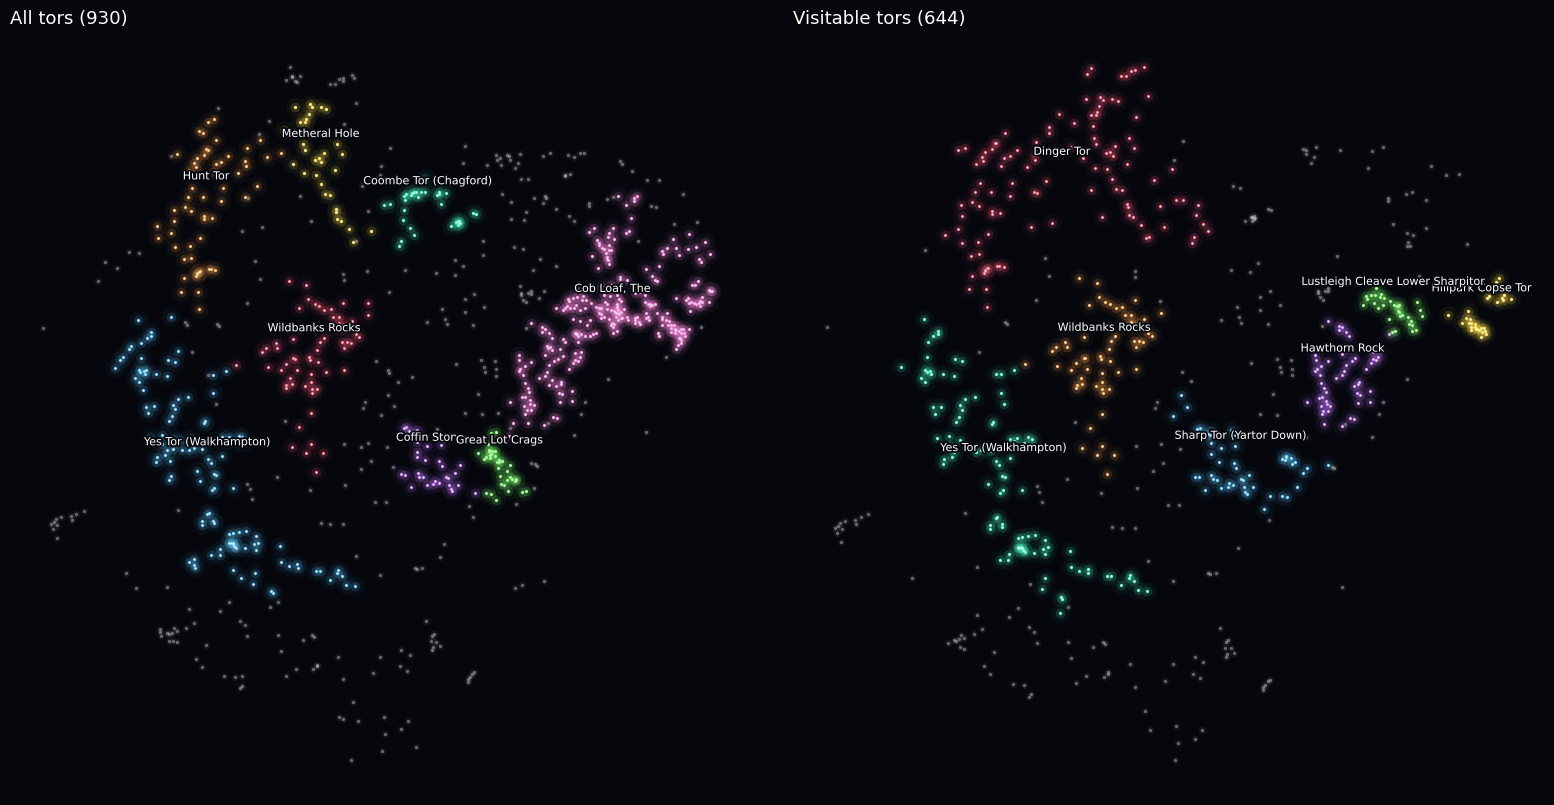

In [61]:
def firefly_plot(ax, g, cluster_col, name_col, title):
    ax.set_facecolor(BG)

    # Noise (-1): tors not in any cluster, dim sparks
    noise = g[g[cluster_col] == -1]
    ax.scatter(noise.geometry.x, noise.geometry.y, s=30, c="white", alpha=0.05, linewidths=0)
    ax.scatter(noise.geometry.x, noise.geometry.y, s=6,  c="white", alpha=0.35, linewidths=0)

    # Clusters: layered glow
    clusters = sorted(c for c in g[cluster_col].unique() if c >= 0)
    for i, c in enumerate(clusters):
        pts = g[g[cluster_col] == c]
        x, y = pts.geometry.x, pts.geometry.y
        col = PALETTE[i % len(PALETTE)]
        ax.scatter(x, y, s=180, c=col, alpha=0.04, linewidths=0)    # outer halo
        ax.scatter(x, y, s=50,  c=col, alpha=0.15, linewidths=0)    # inner halo
        ax.scatter(x, y, s=6,   c=col, alpha=0.95, linewidths=0)    # core
        ax.scatter(x, y, s=1.5, c="white", alpha=0.9, linewidths=0) # hot centre

        # Label the tor at cluster centre
        ax.text(x.mean(), y.mean() + 1200, pts[name_col].iloc[0],
                color="white", fontsize=8, ha="center", va="bottom",
                path_effects=[pe.withStroke(linewidth=2.5, foreground=BG)])

    ax.set_title(title, color="white", fontsize=13, loc="left")
    ax.set_aspect("equal")
    ax.set_axis_off()

fig, axes = plt.subplots(1, 2, figsize=(16, 8), facecolor=BG)

firefly_plot(axes[0], gdf, "cluster_all", "name_all",
             f"All tors ({len(gdf)})")

vis = gdf[gdf["cluster_vis"] != 9999]          # drop non-visitable tors
firefly_plot(axes[1], vis, "cluster_vis", "name_vis",
             f"Visitable tors ({len(vis)})")

plt.tight_layout()
plt.savefig("tors_preview.png", dpi=200, facecolor=BG)
plt.show()

In [65]:
final = gpd.read_file("tors_clustered_visitable_withinboundary.geojson")

final = final[final["cluster_vis"] != 9999]   # just in case non-visitable tors are in the file

print("Visitable tors:", len(final))
print("Clustered:", (final["cluster_vis"] >= 0).sum())
print("Isolated:", (final["cluster_vis"] == -1).sum())
print(final.groupby("name_vis").size().sort_values(ascending=False))

Visitable tors: 636
Clustered: 447
Isolated: 189
name_vis
Scattered                           189
Dinger Tor                          115
Yes Tor (Walkhampton)               105
Wildbanks Rocks                      61
Hawthorn Rock                        54
Sharp Tor (Yartor Down)              50
Lustleigh Cleave Lower Sharpitor     33
Hillpark Copse Tor                   29
dtype: int64
